# Did Anakin Skywalker's language actually change?

Measuring a character's turn to the dark side from screenplay dialogue alone, rebuilt
from a master's project. This notebook loads the results computed by the pipeline
(`make dataset models emotions arc`) and retrains nothing. The full write-up is in
`docs/project_report.pdf`.

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

sys.path.insert(0, str(Path.cwd().parent / "src"))
from anakin_nlp import config
from anakin_nlp.characters import UNALIGNED

dialogue = pd.read_parquet(config.DIALOGUE_PARQUET)
metrics = json.loads((config.REPORTS / "faction_metrics.json").read_text())
results = json.loads((config.REPORTS / "arc_results.json").read_text())
massacre = results["tusken_massacre"]

def figure(name):
    display(Image(filename=str(config.FIGURES / name), width=900))

print(f"{len(dialogue):,} lines of dialogue, {dialogue.character.nunique()} characters")

2,940 lines of dialogue, 64 characters


## 1. The dataset

Three screenplays in three layouts go through one parser. Names are corrected from an
explicit table, and punctuation is kept.

In [2]:
summary = (dialogue.groupby("episode")
           .agg(lines=("text", "size"), characters=("character", "nunique"),
                mean_words=("n_words", "mean")).round(1))
summary.index = [config.EPISODES[i] for i in summary.index]
display(summary)
display(dialogue.groupby("role").agg(lines=("text", "size"), characters=("character", "nunique")))
print(f"{len(UNALIGNED)} characters deliberately left unlabelled:")
for name, reason in sorted(UNALIGNED.items()):
    print(f"  {name:<14} {reason}")

,lines,characters,mean_words
The Phantom Menace,974,36,10.5
Attack of the Clones,950,40,12.7
Revenge of the Sith,1016,20,11.7


,lines,characters
role,,
dark,344,7
light,1670,19
subject,710,1
unaligned,216,37


12 characters deliberately left unlabelled:
  BOBA FETT      child, lines are grief not ideology
  GREEDO         child bully on Tatooine
  JABBA          crime lord, hostile to both camps
  JANGO FETT     mercenary paid by the Separatists
  JIRA           Tatooine bystander
  LAMA SU        Kaminoan cloner, believes he serves the Republic
  SEBULBA        podracing rival
  TAUN WE        Kaminoan cloner, same
  TC-14          protocol droid, no allegiance
  WALD           Tatooine child
  WATTO          slaver and junk dealer, no faction
  ZAM WESELL     contract bounty hunter


## 2. The validation problem

The label belongs to a character, not to a sentence. A random split puts a character's
lines in both training and test, so a model can score by recognising the speaker.
Holding each character out whole gives the honest figure.

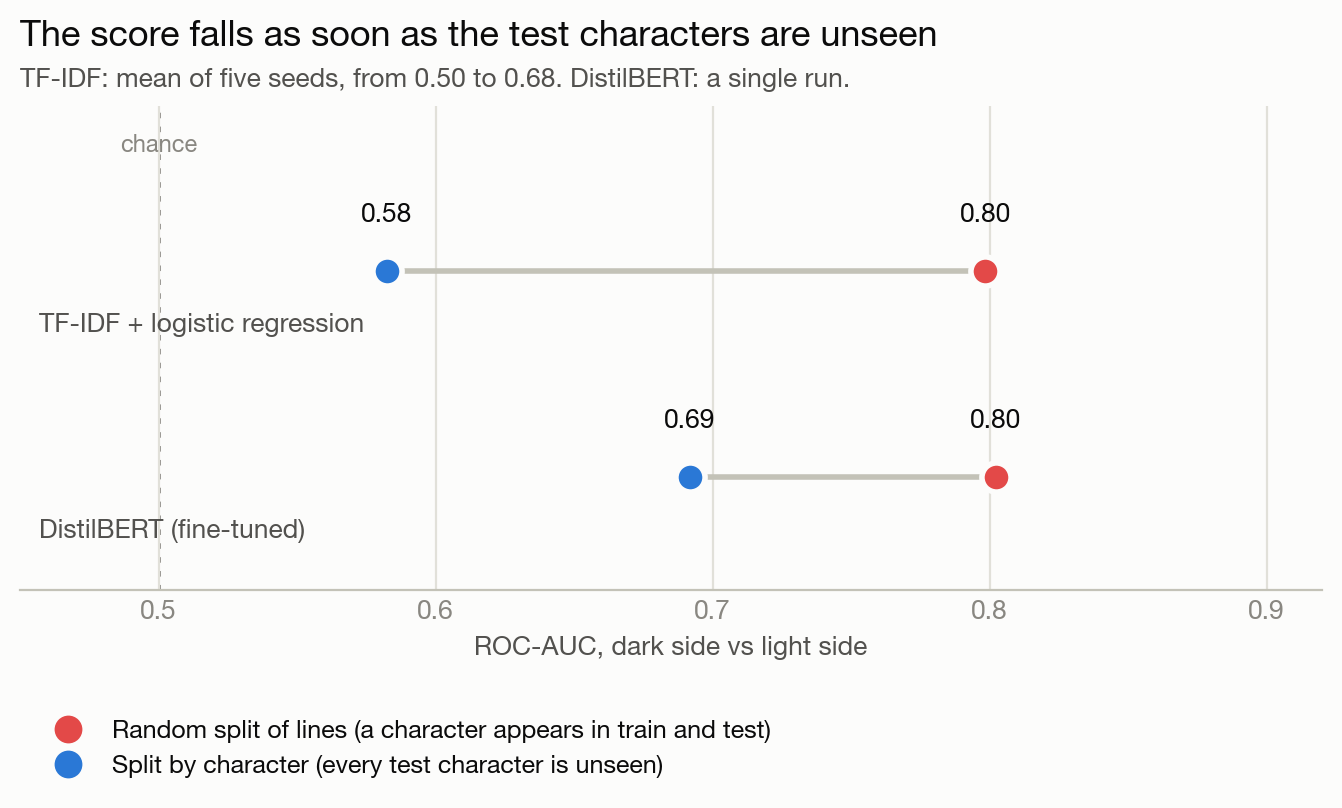

TF-IDF ROC-AUC by seed, split by character: {'42': 0.682, '43': 0.554, '44': 0.497, '45': 0.556, '46': 0.623}
Same folds: {'tfidf': 0.682, 'distilbert': 0.692}
Same folds, without Palpatine: {'tfidf': 0.685, 'distilbert': 0.605}


In [3]:
figure("01_validation_gap.png")
compare = results["model_comparison"]
print("TF-IDF ROC-AUC by seed, split by character:",
      {k: round(v, 3) for k, v in compare["tfidf_grouped_auc_by_seed"].items()})
print("Same folds:", {k: round(v, 3) for k, v in compare["same_folds"].items()})
print("Same folds, without Palpatine:",
      {k: round(v, 3) for k, v in compare["same_folds_without_palpatine"].items()})

TF-IDF falls from 0.80 to 0.58 on average. DistilBERT shows no demonstrated gain: on
identical folds the two models score about the same, and without Palpatine TF-IDF scores
higher.

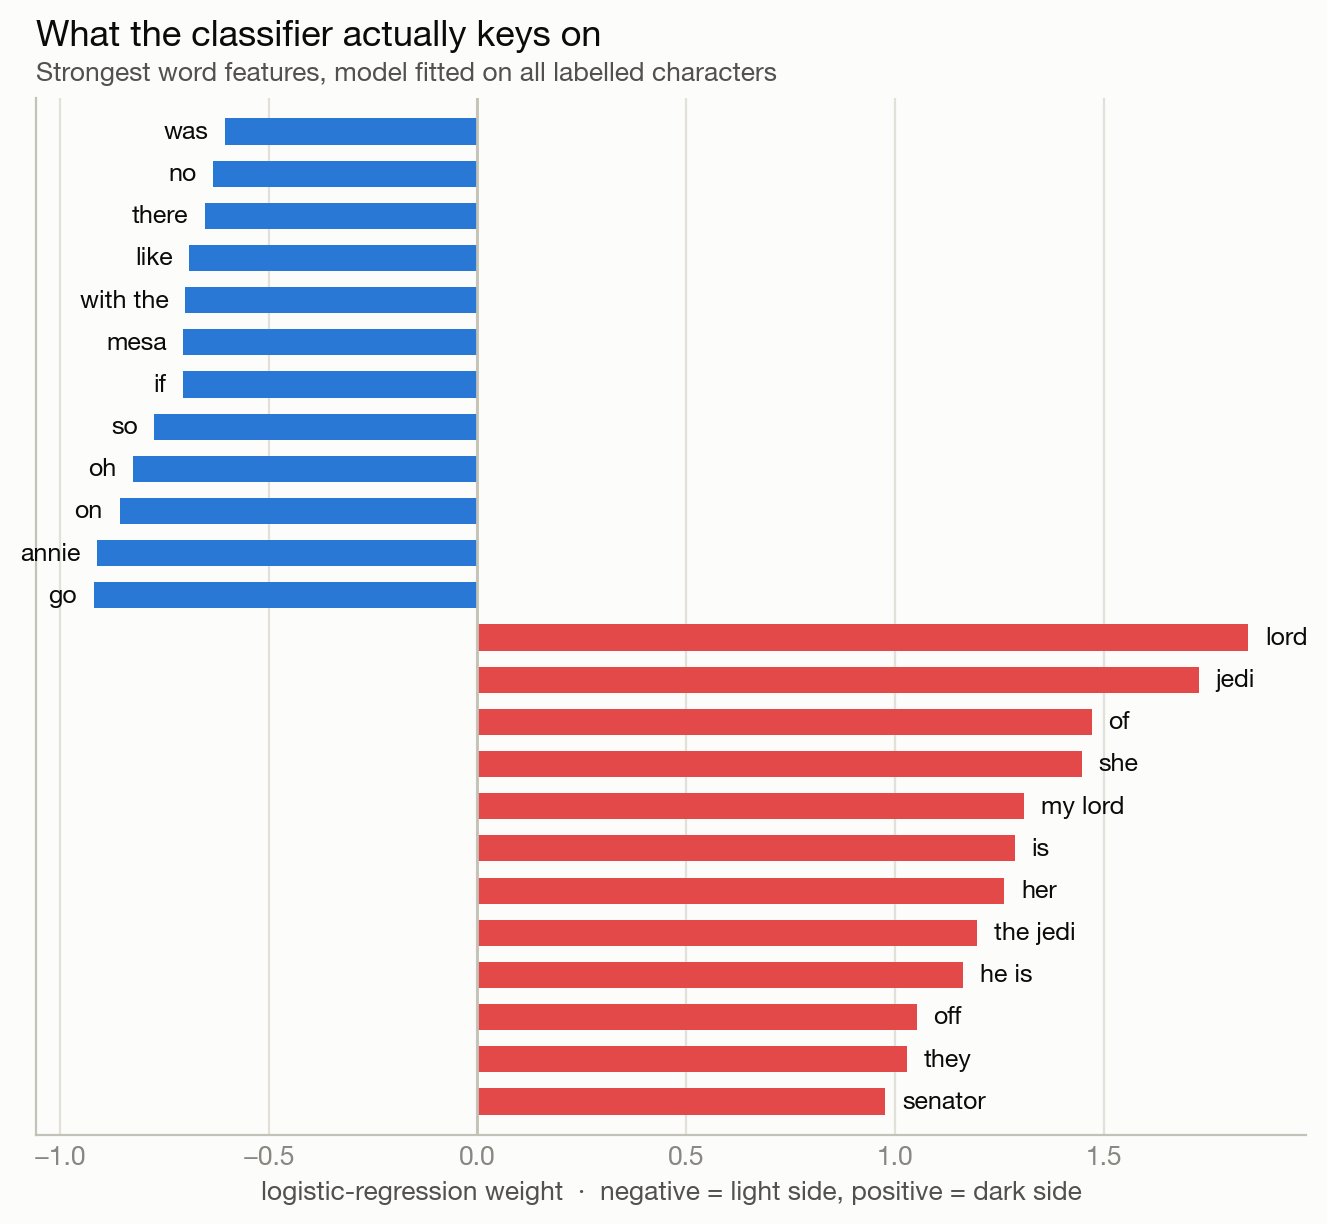

In [4]:
figure("04_top_terms.png")

The weights mix factional vocabulary (`lord`, `senator`) with `mesa`, which is almost
entirely Jar Jar's, and `annie`, the nickname other characters use for
Anakin. Neither says anything about the rhetoric of a camp.

## 3. The Tusken massacre

Anakin says nothing during the massacre. His first words afterwards are in the homestead
garage (Episode II, scene 125). The lower panel below is computed without being told where
that scene is.

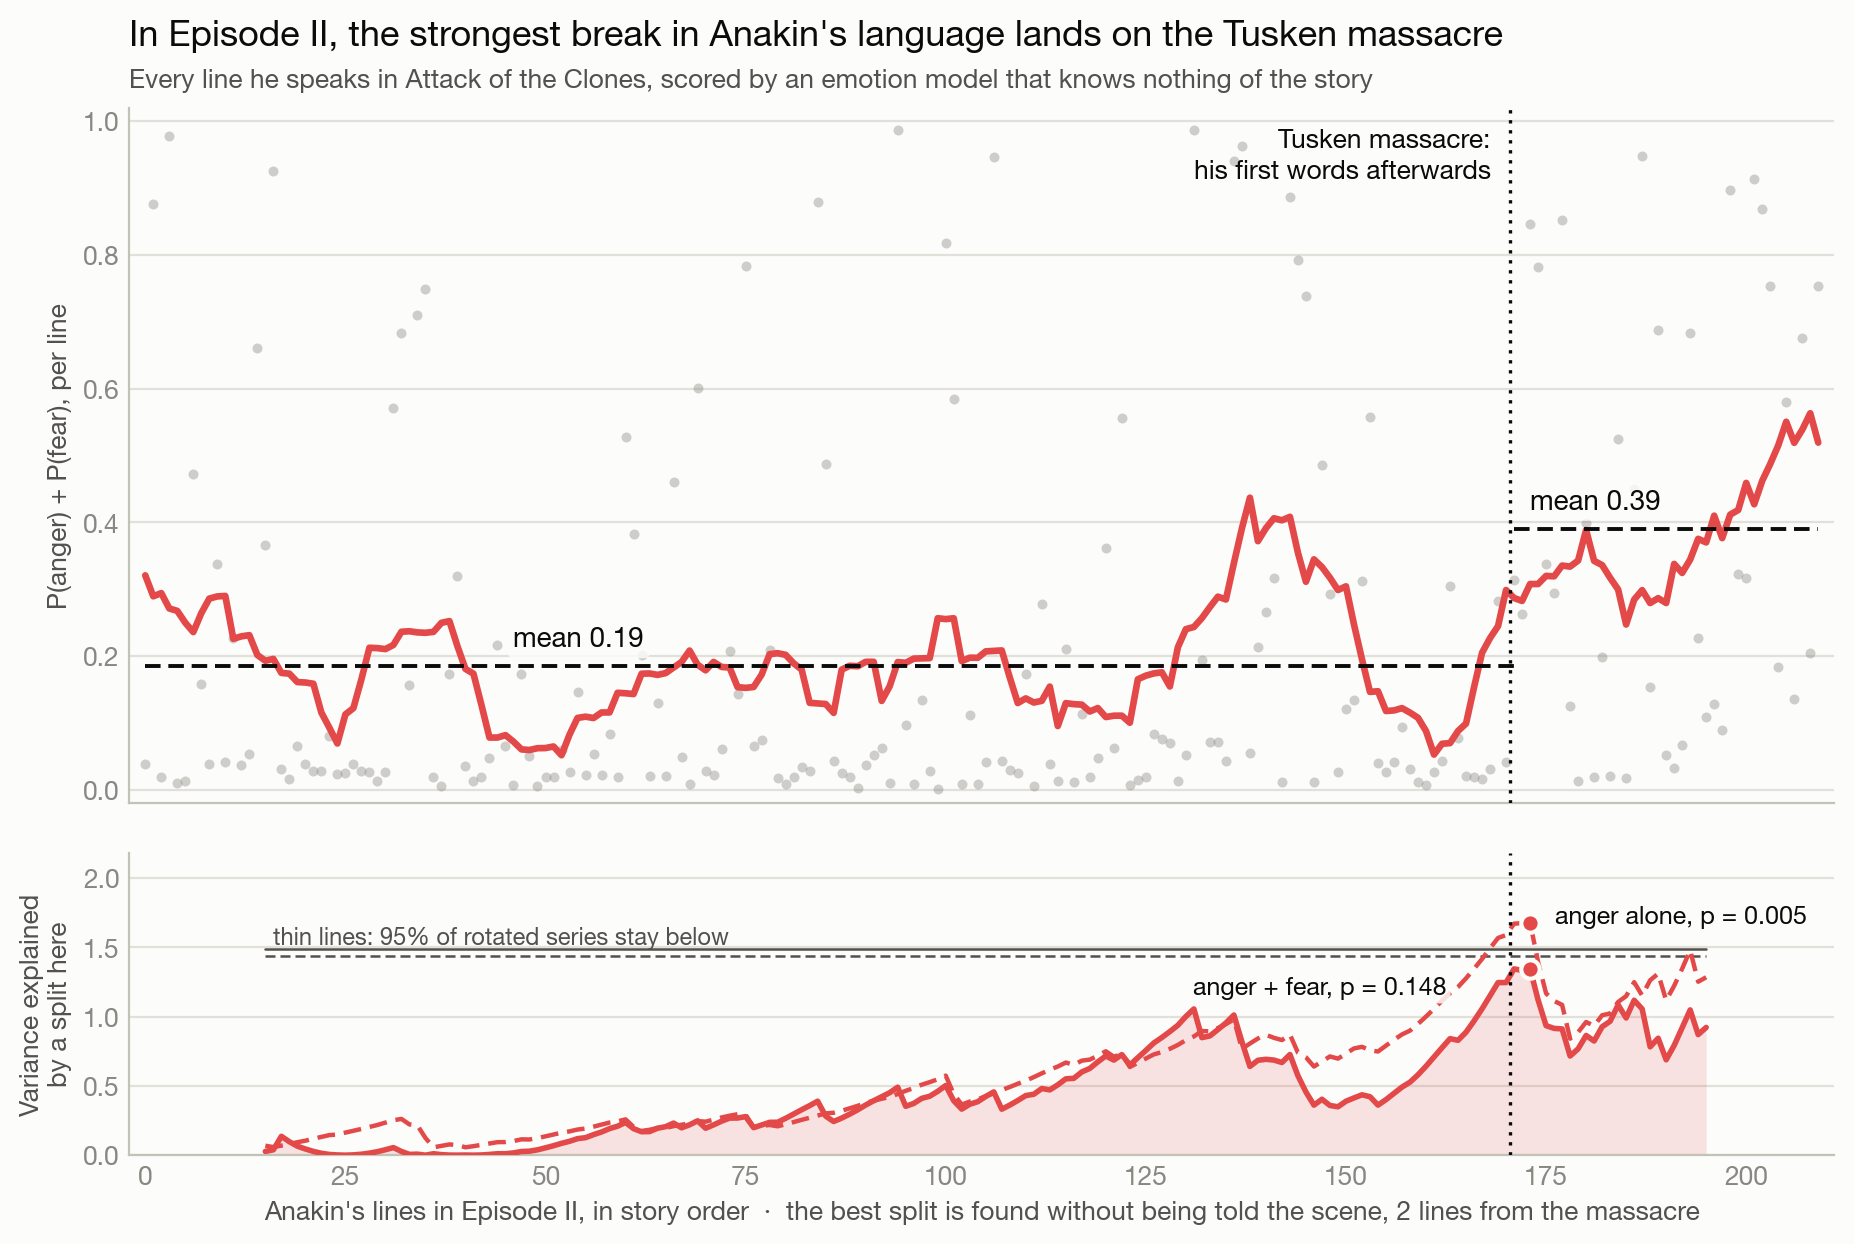

,before,after,step p,blind split: lines from massacre,blind split: scene,blind split p
measure,,,,,,
P(anger) + P(fear),0.185,0.391,0.010,2,125,0.148
P(anger),0.088,0.318,0.005,2,125,0.005
"P(dark side), DistilBERT",0.059,0.269,0.034,1,125,0.080
"P(dark side), TF-IDF",0.279,0.339,0.045,1,118,0.386


Location when scenes are resampled: {'n_resamples': 2000, 'median_scene': 125.0, 'interval_90': [20.950000000000003, 164.0], 'share_on_event_scene': 0.281, 'share_at_or_after_camp': 0.6775, 'most_frequent': {'125': 562, '164': 322, '70': 250, '143': 175, '76': 154}}


In [5]:
figure("00_tusken_break.png")
rows = []
for col, m in massacre["measures"].items():
    rows.append({"measure": m["label"], "before": m["episode_2"]["before"],
                 "after": m["episode_2"]["after"], "step p": m["episode_2"]["p_value"],
                 "blind split: lines from massacre": m["blind_break"]["lines_from_event"],
                 "blind split: scene": m["blind_break"]["scene"],
                 "blind split p": m["blind_break"]["p_value"]})
display(pd.DataFrame(rows).set_index("measure").round(3))
print("Location when scenes are resampled:", massacre["location_uncertainty"])

All four measures rise at the massacre, and all four blind searches land within 2 lines
of it. Only anger clears the bar in the blind search, and the location is a best estimate:
when scenes are resampled the break lands on scene 125 in 28% of runs.

In [6]:
for name, entry in massacre["controls"].items():
    for col, res in entry.items():
        v = res["vs_anakin"]
        print(f"{name:<8} {col:<12} jump {res['step']['difference']:+.3f} | Anakin's extra jump "
              f"{v['difference']:+.3f}, 95% CI [{v['ci_low']:+.3f}, {v['ci_high']:+.3f}]")

OBI-WAN  dark_affect  jump +0.022 | Anakin's extra jump +0.184, 95% CI [-0.013, +0.344]
OBI-WAN  anger        jump +0.019 | Anakin's extra jump +0.210, 95% CI [+0.021, +0.340]
PADME    dark_affect  jump +0.080 | Anakin's extra jump +0.126, 95% CI [-0.058, +0.257]
PADME    anger        jump +0.133 | Anakin's extra jump +0.097, 95% CI [-0.085, +0.244]


Padmé rises at the same point too. Anakin's jump is larger, but the difference from
Padmé's is not statistically clear.

## 4. Across the whole trilogy

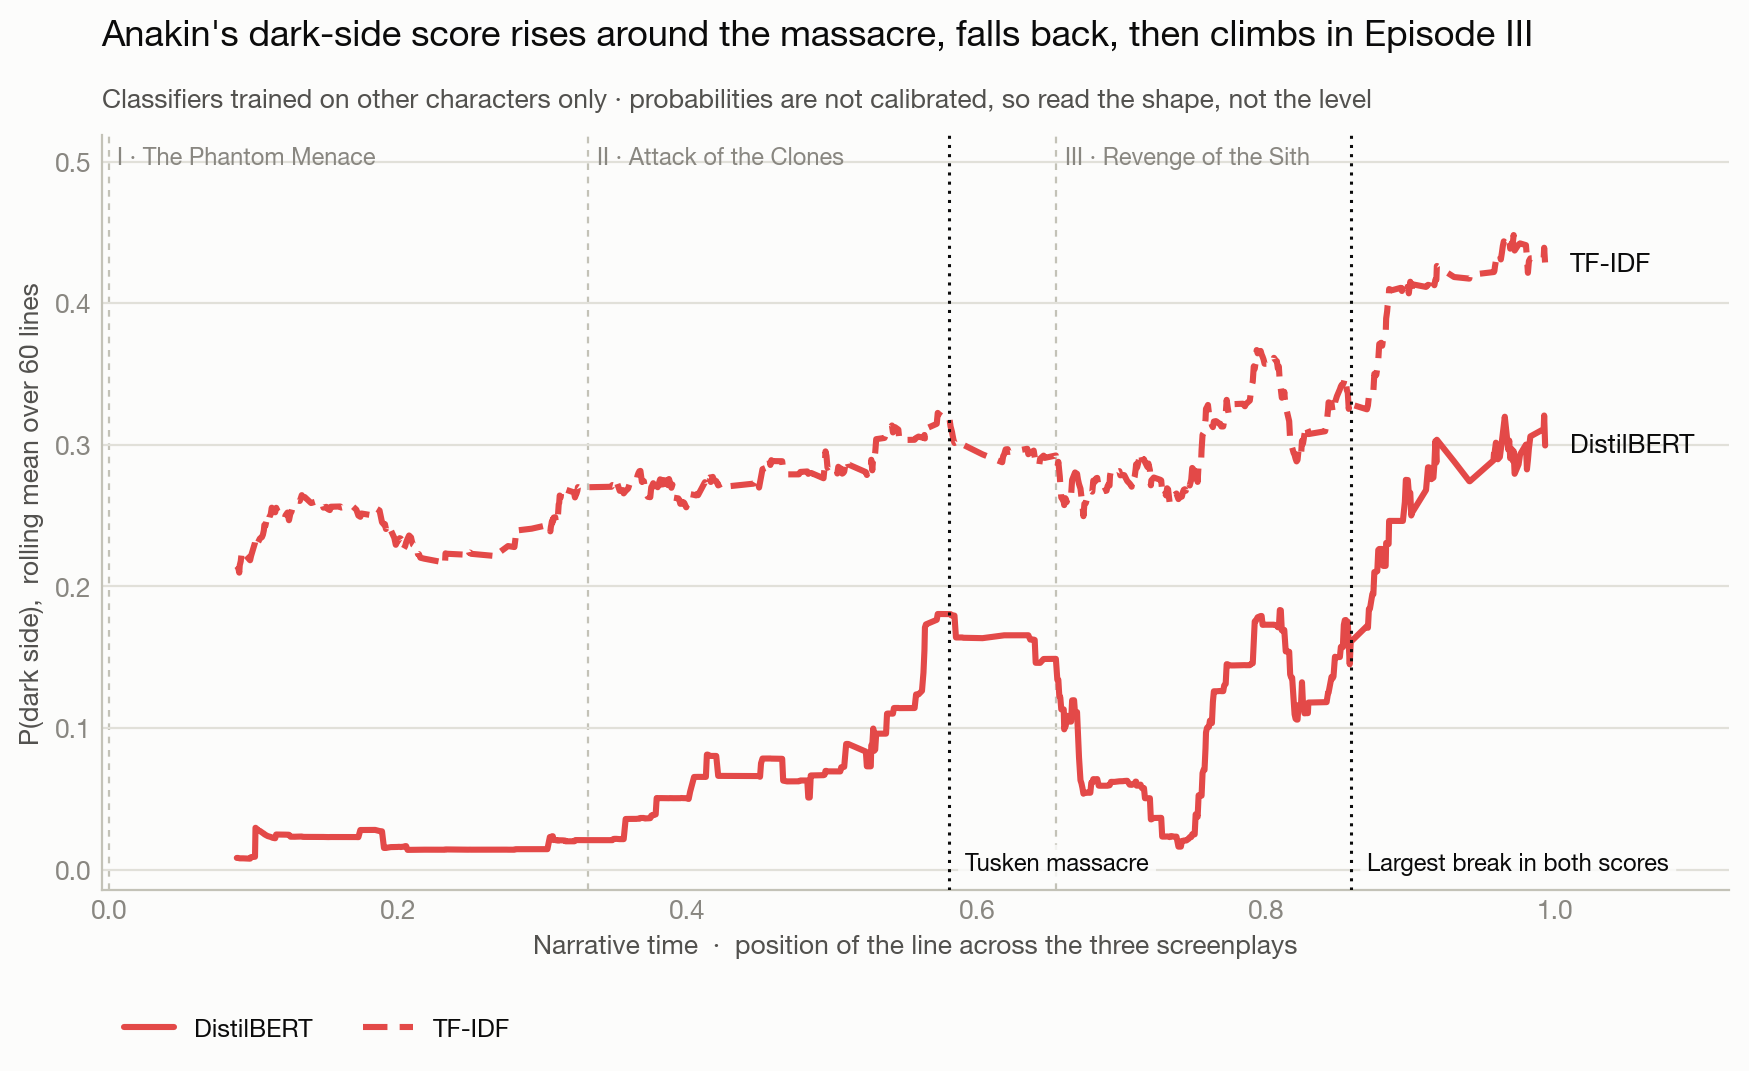

,before_massacre,after_massacre_episode_2,episode_3_first_half,episode_3_second_half
P(anger) + P(fear),0.185,0.391,0.204,0.272
P(anger),0.088,0.318,0.130,0.186
"P(dark side), DistilBERT",0.059,0.269,0.057,0.216
"P(dark side), TF-IDF",0.279,0.339,0.282,0.370


episode  scene  position  before  \
measure                  min lines per side                                     
P(anger) + P(fear)       15                        3    195     0.963   0.213   
                         30                        3    195     0.958   0.213   
                         50                        2     70     0.510   0.185   
P(dark side), TF-IDF     15                        3    103     0.858   0.275   
                         30                        3    103     0.858   0.275   
                         50                        3    103     0.858   0.275   
P(dark side), DistilBERT 15                        3    103     0.858   0.067   
                         30                        3    103     0.858   0.067   
                         50                        3    103     0.858   0.067   

                                             after       p  
measure                  min lines per side                 
P(anger) + P(fear)       15                  0.518  0.0197  
                         30                  0.453  0.0042  
                         50                  0.253  0.0732  
P(dark side), TF-IDF     15                  0.429  0.0016  
                         30                  0.429  0.0016  
                         50                  0.429  0.0016  
P(dark side), DistilBERT 15                  0.294  0.0032  
                         30                  0.294  0.0032  
                         50                  0.294  0.0032

In [7]:
figure("06_dark_score.png")
display(pd.DataFrame({m["label"]: m["levels"] for m in massacre["measures"].values()}).T.round(3))
rows = []
for col in ("dark_affect", "p_dark_tfidf", "p_dark_bert"):
    for size, cp in results[col]["best_break_by_min_size"].items():
        rows.append({"measure": results[col]["measure"], "min lines per side": int(size),
                     "episode": cp["episode"], "scene": cp["scene"],
                     "position": round(cp["position"], 3), "before": round(cp["before"], 3),
                     "after": round(cp["after"], 3), "p": round(cp["p_value"], 4)})
display(pd.DataFrame(rows).set_index(["measure", "min lines per side"]))

The massacre break does not last: both measures return to about their earlier level in
the first half of Episode III. Across the trilogy, both classifiers place the largest break
at the same line in Episode III, just before the Chancellor's office scenes. The single best
break in anger and fear depends on the minimum size allowed.

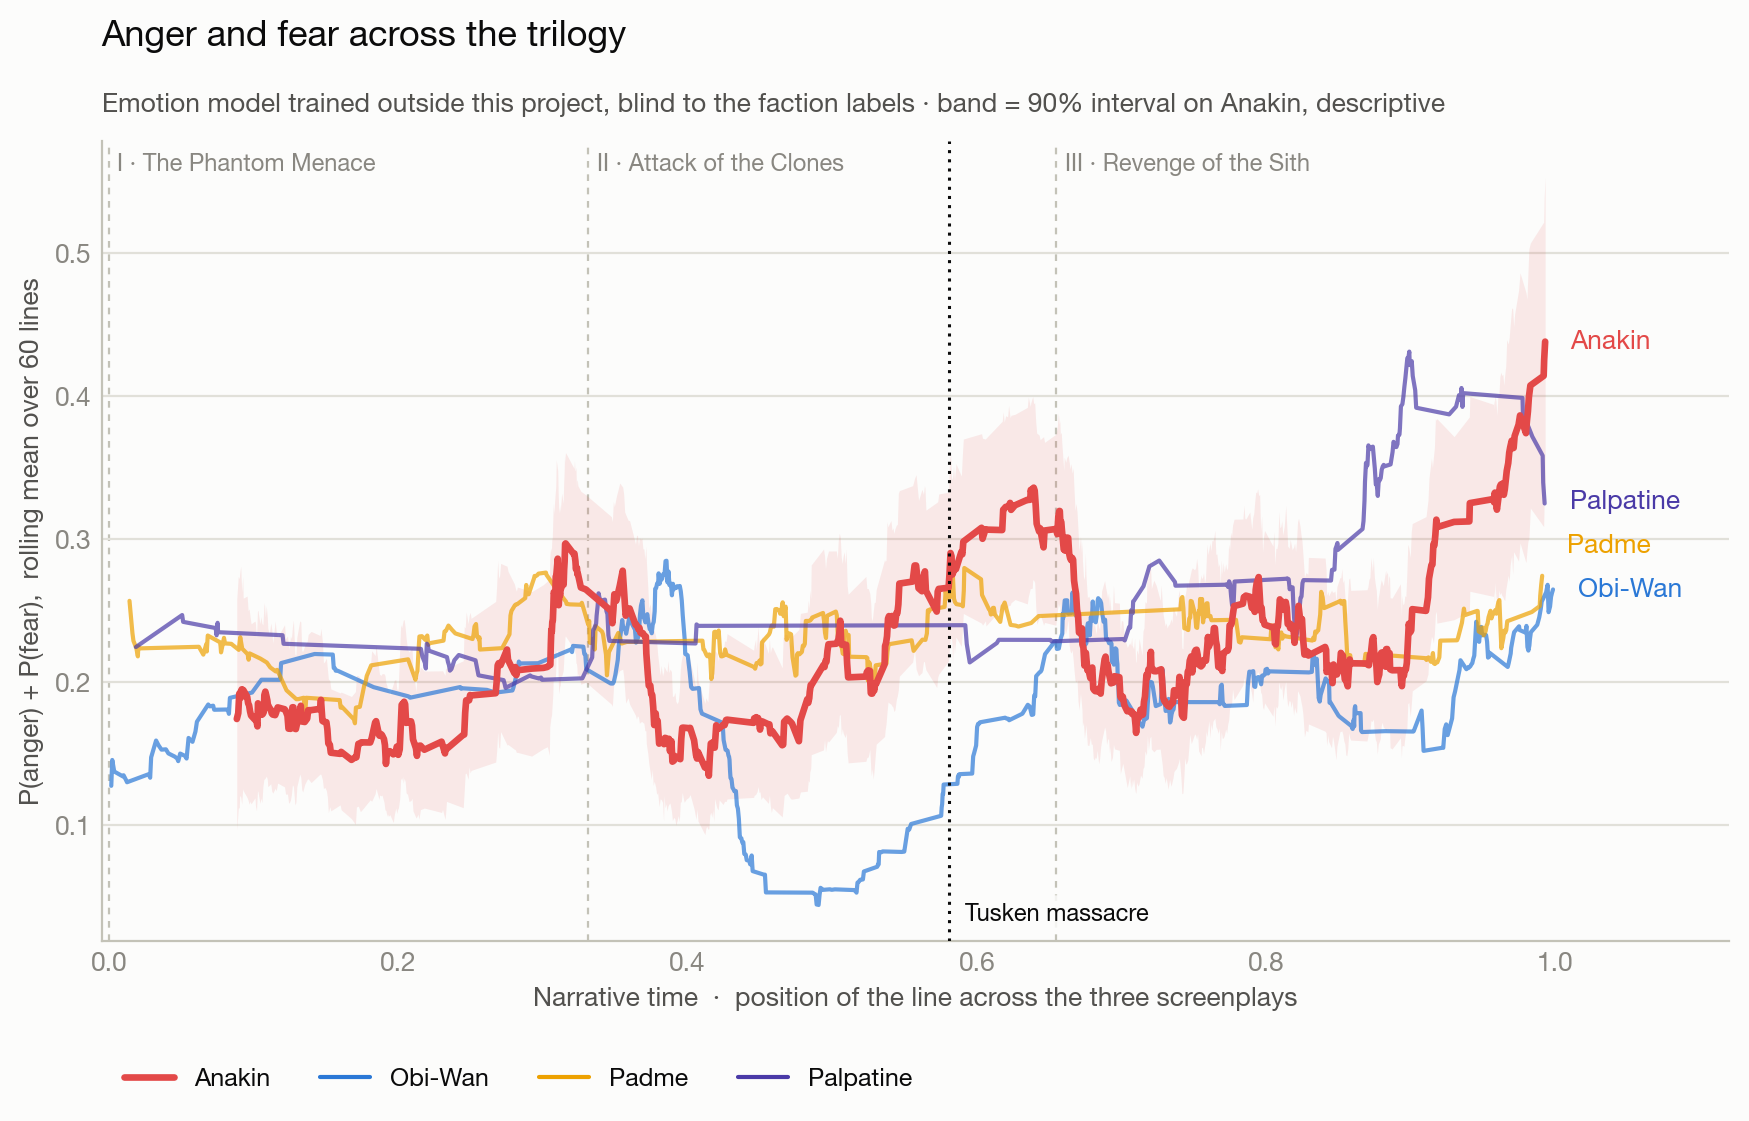

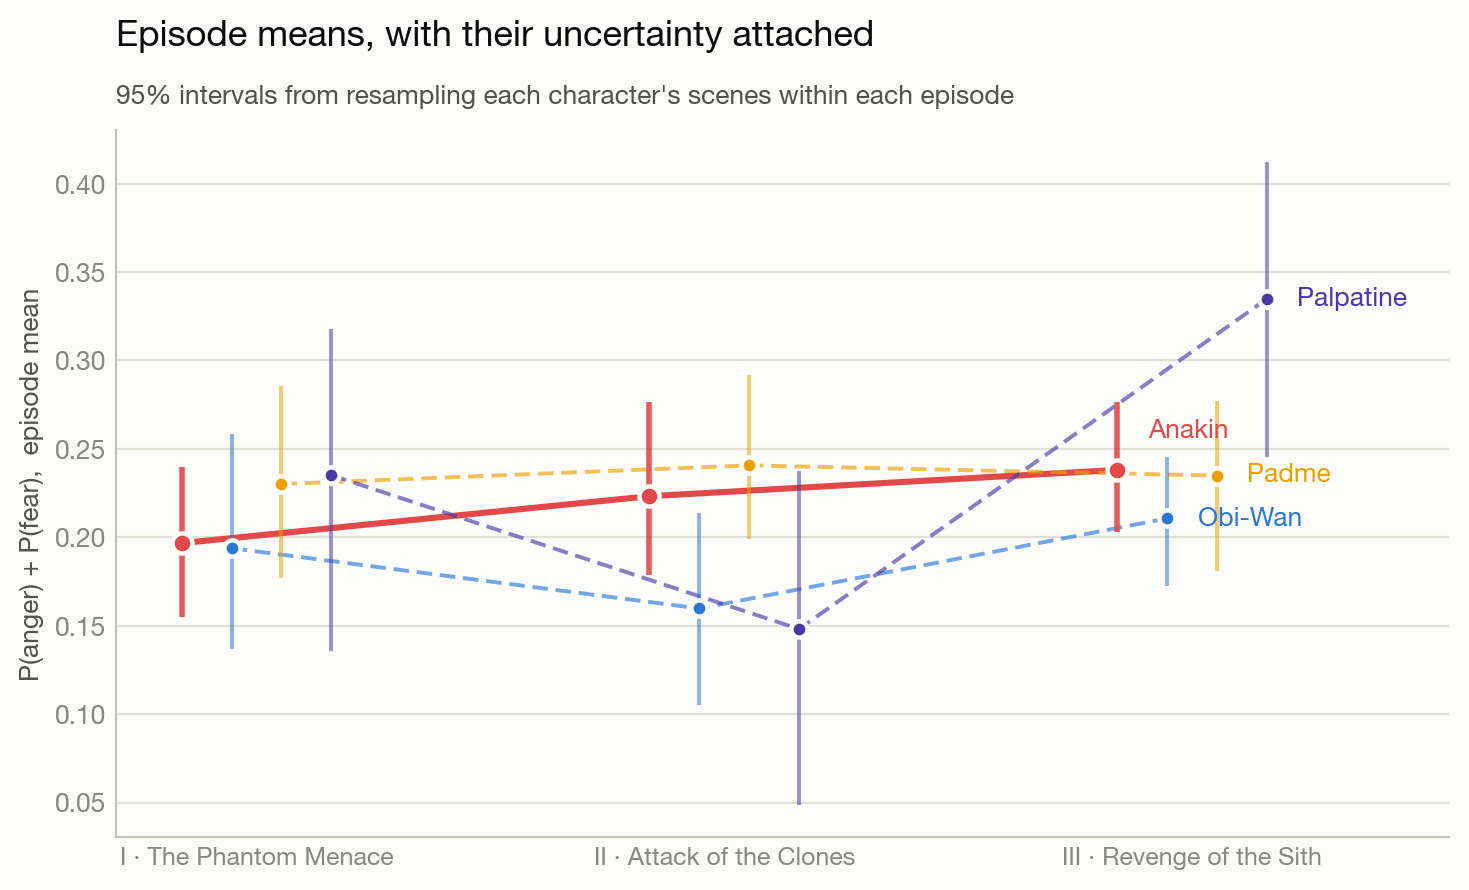

vs pooled light side: +0.103  95% CI [-0.009, +0.213]
vs OBI-WAN    +0.077  95% CI [-0.072, +0.216]
vs PADME      +0.111  95% CI [-0.031, +0.258]
vs PALPATINE  -0.083  95% CI [-0.278, +0.123]


In [8]:
figure("02_emotional_arc.png")
figure("05_by_episode.png")
emo = results["dark_affect"]
c = emo["pooled_light_control"]["contrast"]
print(f"vs pooled light side: {c['difference']:+.3f}  95% CI [{c['ci_low']:+.3f}, {c['ci_high']:+.3f}]")
for name, c in emo["controls"].items():
    print(f"vs {name:<10} {c['difference']:+.3f}  95% CI [{c['ci_low']:+.3f}, {c['ci_high']:+.3f}]")

Anger and fear rise overall, but no comparison with a control excludes zero, so this
overall rise is not clearly his alone.

## 5. Which emotions move

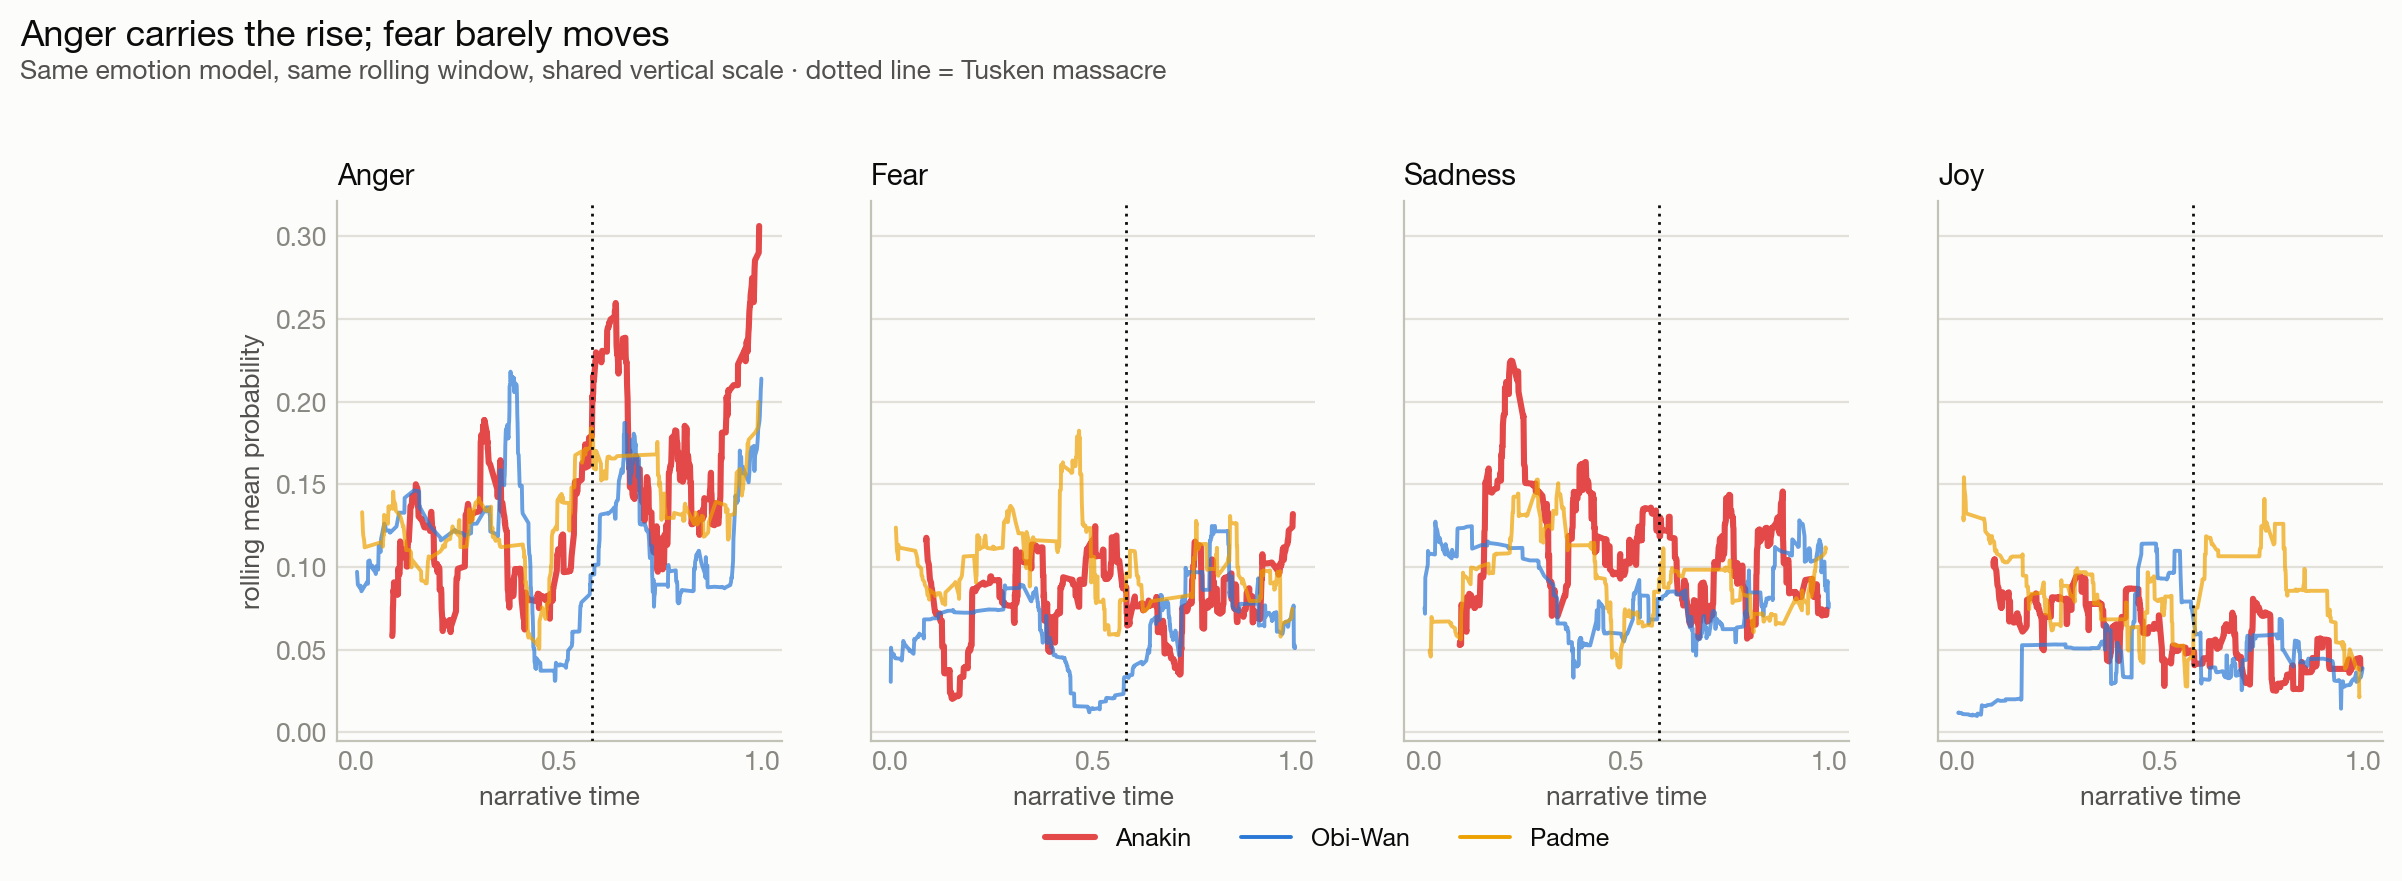

,rho,p_value,p_holm
surprise,-0.234,0.008,0.051
joy,-0.169,0.006,0.039
sadness,-0.034,0.585,0.994
neutral,0.063,0.497,0.994
fear,0.085,0.063,0.254
disgust,0.094,0.013,0.063
anger,0.118,0.070,0.254


{'surprise_with': 0.3988172113895416, 'surprise_without': 0.09738002717494965, 'share_by_episode': {'1': 0.2541436464088398, '2': 0.13333333333333333, '3': 0.19435736677115986}, 'surprise_trend_without_questions': {'rho': -0.2687586965304957, 'p_value': 0.010452961672473868, 'n': 574}}


In [9]:
figure("03_emotion_panels.png")
trends = pd.DataFrame(results["emotions"]["trends"]).T[["rho", "p_value", "p_holm"]].astype(float)
display(trends.sort_values("rho").round(3))
print(results["emotions"]["question_marks"])

Surprise and joy fall more clearly than anger rises. Most of that fall happens between
Episodes I and II, where the script source changes and the character goes from child to young
man.

## Limitations

- Seven dark-side characters, and Palpatine has 52% of their lines.
- Many tests on one small dataset; only the emotion table is adjusted for multiple comparisons.
- The three scripts differ in source and stage, so comparisons within an episode are more
  reliable than comparisons between episodes.
- Story time is line rank, not screen time.
- The models are out of domain and uncalibrated, so trends and contrasts mean more than
  absolute levels.